In [1]:
import torch, torchvision, sklearn, xgboost, shap, cv2, pandas
print(torch.__version__, xgboost.__version__, shap.__version__)
print("CUDA available:", torch.cuda.is_available())  # expected False here

2.14.1+cpu 3.4.1 0.53.0
CUDA available: False


In [2]:
import pandas as pd

files = {
    "crop": "data/Crop_recommendation.csv",
    "fert_A": "data/Fertilizer Prediction.csv",
    "fert_B": "data/fertilizer_recommendation.csv",
}

In [3]:
dfs = {}
for name, path in files.items():
    df = pd.read_csv(path)
    df.columns = [c.strip() for c in df.columns]
    dfs[name] = df
    print(f"\n===== {name} =====")
    print("shape:", df.shape)
    print("columns:", list(df.columns))
    print("missing:", int(df.isna().sum().sum()), "| duplicates:", int(df.duplicated().sum()))
    display(df.head(3))

print("\nCrop classes:", dfs["crop"]["label"].nunique())
print("\nfert_A target counts:\n", dfs["fert_A"].iloc[:, -1].value_counts())
print("\nfert_B last-column counts:\n", dfs["fert_B"].iloc[:, -1].value_counts().head(15))


===== crop =====
shape: (2200, 10)
columns: ['Nitrogen', 'phosphorus', 'potassium', 'temperature', 'humidity', 'ph', 'rainfall', 'label', 'Unnamed: 8', 'Unnamed: 9']
missing: 4400 | duplicates: 0


,Nitrogen,phosphorus,potassium,temperature,humidity,ph,rainfall,label,Unnamed: 8,Unnamed: 9
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice,NaN,NaN
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice,NaN,NaN
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice,NaN,NaN



===== fert_A =====
shape: (99, 9)
columns: ['Temparature', 'Humidity', 'Moisture', 'Soil Type', 'Crop Type', 'Nitrogen', 'Potassium', 'Phosphorous', 'Fertilizer Name']
missing: 0 | duplicates: 0


,Temparature,Humidity,Moisture,Soil Type,Crop Type,Nitrogen,Potassium,Phosphorous,Fertilizer Name
0,26,52,38,Sandy,Maize,37,0,0,Urea
1,29,52,45,Loamy,Sugarcane,12,0,36,DAP
2,34,65,62,Black,Cotton,7,9,30,14-35-14



===== fert_B =====
shape: (10000, 20)
columns: ['Soil_Type', 'Soil_pH', 'Soil_Moisture', 'Organic_Carbon', 'Electrical_Conductivity', 'Nitrogen_Level', 'Phosphorus_Level', 'Potassium_Level', 'Temperature', 'Humidity', 'Rainfall', 'Crop_Type', 'Crop_Growth_Stage', 'Season', 'Irrigation_Type', 'Previous_Crop', 'Region', 'Fertilizer_Used_Last_Season', 'Yield_Last_Season', 'Recommended_Fertilizer']
missing: 0 | duplicates: 0


,Soil_Type,Soil_pH,Soil_Moisture,Organic_Carbon,Electrical_Conductivity,Nitrogen_Level,Phosphorus_Level,Potassium_Level,Temperature,Humidity,Rainfall,Crop_Type,Crop_Growth_Stage,Season,Irrigation_Type,Previous_Crop,Region,Fertilizer_Used_Last_Season,Yield_Last_Season,Recommended_Fertilizer
0,Clay,6.07,34.98,0.32,1.87,61,44,84,19.84,83.31,1693.22,Cotton,Harvest,Kharif,Canal,Wheat,South,297.15,1.19,MOP
1,Silt,6.39,47.34,0.28,0.21,59,56,18,24.40,46.27,1030.21,Maize,Vegetative,Kharif,Sprinkler,Potato,Central,77.17,4.40,Urea
2,Sandy,7.92,38.13,0.99,1.88,43,21,119,24.82,71.86,1166.16,Cotton,Flowering,Kharif,Rainfed,Tomato,South,128.93,7.21,Urea



Crop classes: 22

fert_A target counts:
 Fertilizer Name
Urea        22
DAP         18
28-28       17
14-35-14    14
20-20       14
17-17-17     7
10-26-26     7
Name: count, dtype: int64

fert_B last-column counts:
 Recommended_Fertilizer
Urea             3101
DAP              2920
MOP              1408
Compost           996
Zinc Sulphate     752
NPK               641
SSP               182
Name: count, dtype: int64


In [4]:
crop = pd.read_csv("data/Crop_recommendation.csv")
crop = crop.loc[:, ~crop.columns.str.startswith("Unnamed")]          # drop the empty columns
crop.columns = [c.strip() for c in crop.columns]
crop = crop.rename(columns={"Nitrogen": "N", "phosphorus": "P", "potassium": "K"})

print(crop.shape)                 # expect (2200, 8)
print(list(crop.columns))         # ['N','P','K','temperature','humidity','ph','rainfall','label']
print(crop.isna().sum().sum())    # expect 0
print(crop["label"].nunique(), "crops,", crop["label"].value_counts().min(), "min samples per class")

(2200, 8)
['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label']
0
22 crops, 100 min samples per class


In [5]:
import numpy as np
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.preprocessing import LabelEncoder
from xgboost import XGBClassifier

fb = dfs["fert_B"].copy()
y = LabelEncoder().fit_transform(fb["Recommended_Fertilizer"])
X = pd.get_dummies(fb.drop(columns=["Recommended_Fertilizer"]), drop_first=False)

majority = np.bincount(y).max() / len(y)
cv = StratifiedKFold(5, shuffle=True, random_state=42)
clf = XGBClassifier(n_estimators=200, max_depth=5, learning_rate=0.1,
                    eval_metric="mlogloss", random_state=42, n_jobs=-1)
scores = cross_val_score(clf, X, y, cv=cv, scoring="accuracy")

print(f"majority-class baseline: {majority:.3f}")
print(f"XGBoost 5-fold accuracy: {scores.mean():.3f} +/- {scores.std():.3f}")

# Which features matter?
clf.fit(X, y)
imp = pd.Series(clf.feature_importances_, index=X.columns).sort_values(ascending=False)
print(imp.head(12))

majority-class baseline: 0.310
XGBoost 5-fold accuracy: 0.884 +/- 0.006
Nitrogen_Level                  0.237019
Phosphorus_Level                0.173032
Crop_Growth_Stage_Vegetative    0.101917
Potassium_Level                 0.085642
Soil_pH                         0.074579
Crop_Growth_Stage_Flowering     0.011534
Region_East                     0.009247
Crop_Growth_Stage_Harvest       0.009078
Temperature                     0.009049
Previous_Crop_Wheat             0.009028
Previous_Crop_Maize             0.008925
Previous_Crop_Cotton            0.008895
dtype: float32


In [6]:
core = ["Soil_Type", "Soil_pH", "Soil_Moisture", "Organic_Carbon", "Electrical_Conductivity",
        "Nitrogen_Level", "Phosphorus_Level", "Potassium_Level",
        "Temperature", "Humidity", "Rainfall", "Crop_Type", "Crop_Growth_Stage", "Season"]

Xr = pd.get_dummies(fb[core])
scores_r = cross_val_score(clf, Xr, y, cv=cv, scoring="accuracy")
print(f"full  ({X.shape[1]} cols): {scores.mean():.3f}")
print(f"core  ({Xr.shape[1]} cols): {scores_r.mean():.3f} +/- {scores_r.std():.3f}")

full  (46 cols): 0.884
core  (28 cols): 0.884 +/- 0.007


               precision    recall  f1-score   support

      Compost       0.85      0.82      0.84       199
          DAP       0.96      0.93      0.95       584
          MOP       0.88      0.88      0.88       282
          NPK       0.72      0.73      0.72       128
          SSP       0.08      0.05      0.06        37
         Urea       0.93      0.94      0.94       620
Zinc Sulphate       0.67      0.77      0.72       150

     accuracy                           0.88      2000
    macro avg       0.73      0.73      0.73      2000
 weighted avg       0.87      0.88      0.87      2000



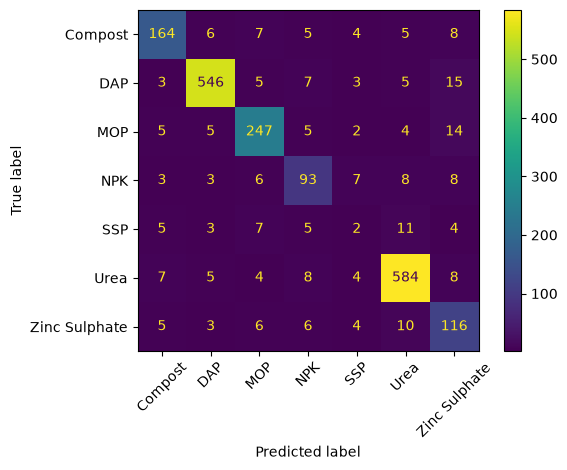

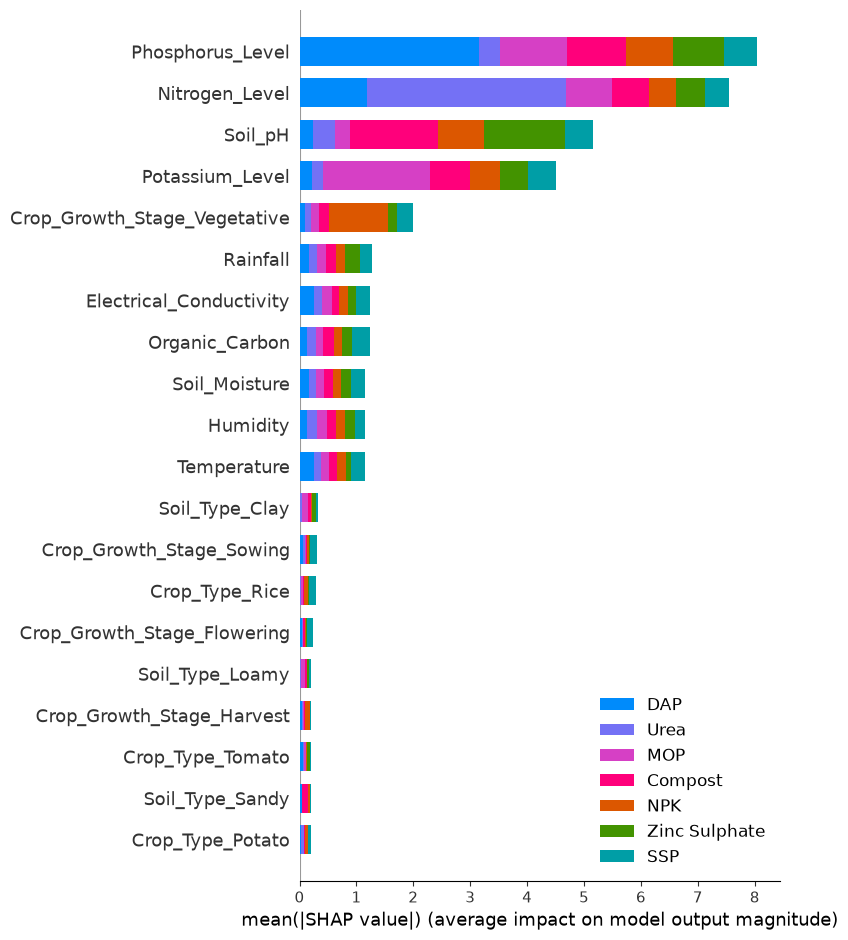

['models/fert_model.joblib']

In [7]:
import joblib, shap, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

le_f = LabelEncoder().fit(fb["Recommended_Fertilizer"])
y = le_f.transform(fb["Recommended_Fertilizer"])
X_tr, X_te, y_tr, y_te = train_test_split(Xr, y, test_size=0.2, stratify=y, random_state=42)

fert_model = XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.08,
                           subsample=0.9, colsample_bytree=0.9,
                           eval_metric="mlogloss", random_state=42, n_jobs=-1)
fert_model.fit(X_tr, y_tr)
pred = fert_model.predict(X_te)

print(classification_report(y_te, pred, target_names=le_f.classes_))
ConfusionMatrixDisplay.from_predictions(y_te, pred, display_labels=le_f.classes_,
                                        xticks_rotation=45)
plt.tight_layout(); plt.show()

sv = shap.TreeExplainer(fert_model).shap_values(X_te)
shap.summary_plot(sv, X_te, class_names=le_f.classes_, plot_type="bar")

import os; os.makedirs("models", exist_ok=True)
joblib.dump({"model": fert_model, "label_encoder": le_f, "columns": list(Xr.columns)},
            "models/fert_model.joblib")

In [8]:
feats = ["N", "P", "K", "temperature", "humidity", "ph", "rainfall"]
le_c = LabelEncoder().fit(crop["label"])
yc = le_c.transform(crop["label"])
Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(crop[feats], yc, test_size=0.2,
                                              stratify=yc, random_state=42)
crop_model = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.08,
                           eval_metric="mlogloss", random_state=42, n_jobs=-1)
crop_model.fit(Xc_tr, yc_tr)
pc = crop_model.predict(Xc_te)
print(classification_report(yc_te, pc, target_names=le_c.classes_))
joblib.dump({"model": crop_model, "label_encoder": le_c, "columns": feats},
            "models/crop_model.joblib")

              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       0.95      1.00      0.98        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       1.00      1.00      1.00        20
      grapes       1.00      1.00      1.00        20
        jute       0.95      1.00      0.98        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       1.00      0.85      0.92        20
       maize       1.00      1.00      1.00        20
       mango       1.00      1.00      1.00        20
   mothbeans       0.95      1.00      0.98        20
    mungbean       0.91      1.00      0.95        20
   muskmelon       1.00      1.00      1.00        20
      orange       1.00      1.00      1.00        20
      papaya       1.00    

['models/crop_model.joblib']

In [9]:
from sklearn.utils.class_weight import compute_sample_weight

# 1) Does class-weighting rescue SSP?
w = compute_sample_weight("balanced", y_tr)
m2 = XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.08,
                   subsample=0.9, colsample_bytree=0.9,
                   eval_metric="mlogloss", random_state=42, n_jobs=-1)
m2.fit(X_tr, y_tr, sample_weight=w)
print(classification_report(y_te, m2.predict(X_te), target_names=le_f.classes_))

# 2) Do SSP rows look different from the rest on the key features?
key = ["Nitrogen_Level", "Phosphorus_Level", "Potassium_Level", "Soil_pH"]
tmp = fb.assign(is_ssp=(fb["Recommended_Fertilizer"] == "SSP"))
print(tmp.groupby("is_ssp")[key].agg(["mean", "std"]).round(2))

               precision    recall  f1-score   support

      Compost       0.85      0.82      0.84       199
          DAP       0.98      0.92      0.95       584
          MOP       0.92      0.86      0.89       282
          NPK       0.66      0.75      0.70       128
          SSP       0.10      0.19      0.13        37
         Urea       0.98      0.94      0.96       620
Zinc Sulphate       0.68      0.83      0.75       150

     accuracy                           0.88      2000
    macro avg       0.74      0.76      0.74      2000
 weighted avg       0.90      0.88      0.89      2000

       Nitrogen_Level        Phosphorus_Level        Potassium_Level         \
                 mean    std             mean    std            mean    std   
is_ssp                                                                        
False           88.63  40.43            48.69  23.24           63.86  31.95   
True           108.58  29.05            63.64  14.60           79.69  22.24 

In [10]:
joblib.dump({"model": m2, "label_encoder": le_f, "columns": list(Xr.columns)},
            "models/fert_model.joblib")

def top3(model, le, X_row):
    p = model.predict_proba(X_row)[0]
    idx = p.argsort()[::-1][:3]
    return [(le.classes_[i], round(float(p[i]), 3)) for i in idx]

# Sanity check on a few test rows
for i in range(3):
    print("true:", le_f.classes_[y_te[i]], "| top3:", top3(m2, le_f, X_te.iloc[[i]]))

true: Compost | top3: [('Compost', 0.998), ('MOP', 0.001), ('DAP', 0.001)]
true: Urea | top3: [('Urea', 0.999), ('DAP', 0.0), ('NPK', 0.0)]
true: SSP | top3: [('SSP', 0.425), ('MOP', 0.237), ('Urea', 0.145)]


In [11]:
print(sorted(fb["Soil_Type"].unique()))
print(sorted(fb["Crop_Type"].unique()))
print(sorted(fb["Crop_Growth_Stage"].unique()), sorted(fb["Season"].unique()))

['Clay', 'Loamy', 'Sandy', 'Silt']
['Cotton', 'Maize', 'Potato', 'Rice', 'Sugarcane', 'Tomato', 'Wheat']
['Flowering', 'Harvest', 'Sowing', 'Vegetative'] ['Kharif', 'Rabi', 'Zaid']


In [12]:
import json
num = ["Soil_pH", "Soil_Moisture", "Organic_Carbon", "Electrical_Conductivity", "Nitrogen_Level",
       "Phosphorus_Level", "Potassium_Level", "Temperature", "Humidity", "Rainfall"]
feats = ["N", "P", "K", "temperature", "humidity", "ph", "rainfall"]

cfg = {
    "fert_defaults": {**fb[["Soil_Moisture", "Organic_Carbon", "Electrical_Conductivity"]].median().round(3).to_dict(),
                      "Soil_Type": fb["Soil_Type"].mode()[0]},
    "ranges": {"crop": {c: [float(crop[c].min()), float(crop[c].max())] for c in feats},
               "fert": {c: [float(fb[c].min()), float(fb[c].max())] for c in num}},
}
json.dump(cfg, open("models/inference_config.json", "w"), indent=2)
print(cfg["fert_defaults"])

{'Soil_Moisture': 35.645, 'Organic_Carbon': 0.85, 'Electrical_Conductivity': 1.53, 'Soil_Type': 'Sandy'}


In [13]:
from sklearn.model_selection import cross_validate

variants = {
    "all 14 (current)": core,
    "no Rainfall": [c for c in core if c != "Rainfall"],
    "no Rainfall/Temp/Humidity": [c for c in core if c not in ("Rainfall", "Temperature", "Humidity")],
    "only N,P,K,pH + soil/crop/stage/season": ["Soil_Type", "Soil_pH", "Nitrogen_Level", "Phosphorus_Level",
                                                "Potassium_Level", "Crop_Type", "Crop_Growth_Stage", "Season"],
}
for name, cols_ in variants.items():
    r = cross_validate(clf, pd.get_dummies(fb[cols_]), y, cv=cv, scoring=["accuracy", "f1_macro"])
    print(f"{name:42s} acc {r['test_accuracy'].mean():.3f} | macro-F1 {r['test_f1_macro'].mean():.3f}")

print(cfg["ranges"]["crop"]["rainfall"], cfg["ranges"]["fert"]["Rainfall"])
print(crop.groupby("label")[feats].mean().round(1).loc[["rice", "jute"]])

all 14 (current)                           acc 0.884 | macro-F1 0.743
no Rainfall                                acc 0.884 | macro-F1 0.743
no Rainfall/Temp/Humidity                  acc 0.883 | macro-F1 0.747
only N,P,K,pH + soil/crop/stage/season     acc 0.884 | macro-F1 0.750
[20.21126747, 298.5601175] [200.08, 2999.98]
          N     P     K  temperature  humidity   ph  rainfall
label                                                        
rice   79.9  47.6  39.9         23.7      82.3  6.4     236.2
jute   78.4  46.9  40.0         25.0      79.6  6.7     174.8


In [14]:
final_cols = [c for c in core if c not in ("Rainfall", "Temperature", "Humidity")]   # edit to your chosen set
from sklearn.utils.class_weight import compute_sample_weight
Xf = pd.get_dummies(fb[final_cols])
X_tr, X_te, y_tr, y_te = train_test_split(Xf, y, test_size=0.2, stratify=y, random_state=42)
m3 = XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.08, subsample=0.9,
                   colsample_bytree=0.9, eval_metric="mlogloss", random_state=42, n_jobs=-1)
m3.fit(X_tr, y_tr, sample_weight=compute_sample_weight("balanced", y_tr))
print(classification_report(y_te, m3.predict(X_te), target_names=le_f.classes_))

joblib.dump({"model": m3, "label_encoder": le_f, "columns": list(Xf.columns)}, "models/fert_model.joblib")
cfg["ranges"]["fert"] = {c: [float(fb[c].min()), float(fb[c].max())] for c in num if c in final_cols}
json.dump(cfg, open("models/inference_config.json", "w"), indent=2)

               precision    recall  f1-score   support

      Compost       0.87      0.81      0.84       199
          DAP       0.98      0.92      0.95       584
          MOP       0.90      0.85      0.88       282
          NPK       0.66      0.77      0.71       128
          SSP       0.10      0.24      0.15        37
         Urea       0.98      0.93      0.96       620
Zinc Sulphate       0.71      0.80      0.75       150

     accuracy                           0.87      2000
    macro avg       0.74      0.76      0.75      2000
 weighted avg       0.90      0.87      0.89      2000

